# Experiment 27: Deep Belief Network Representation Learning

A postal service has few labelled handwritten digits and many unlabelled examples. We simulate 28×28 digit-like patterns, greedily pre-train two RBMs, transfer their weights to a Keras classifier and compare with random initialisation.

**Tools:** NumPy, SciPy, TensorFlow, Keras, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Train two stacked RBMs layer by layer (784–128–64).  2. Visualise first-layer filters.  3. Transfer weights to a dense network and fine-tune on 1,000 labels.  4. Train the same network from random initialisation.  5. Compare accuracy and 2-D learned representations.

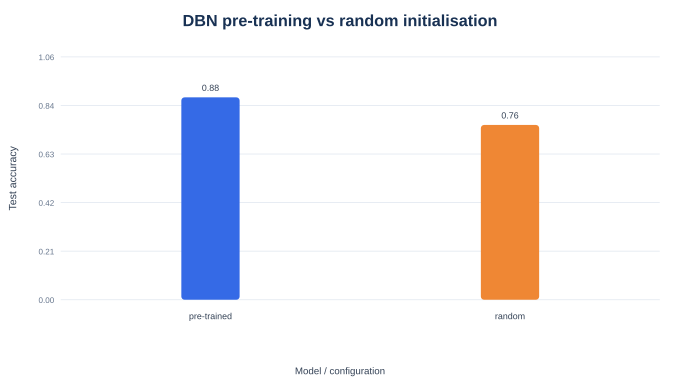

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from scipy.special import expit
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

tf.keras.utils.set_random_seed(27)
rng=np.random.default_rng(27)
# Ten simple 28x28 class prototypes with noise: a stand-in for a labelled digit subset.
n=1400;imgs=np.zeros((n,28,28));labels=np.arange(n)%10
for i,c in enumerate(labels):
    im=np.zeros((28,28))
    im[:,3+c:5+c]=1;im[2+c:4+c,:]=.7
    if c%2:im[10:12,:]=1
    im=np.clip(im+rng.normal(0,.18,im.shape),0,1);imgs[i]=im
X=(imgs.reshape(n,-1)>.5).astype(float)
Xtr,Xte,ytr,yte=train_test_split(X,labels,test_size=.25,random_state=27,stratify=labels)
unlabelled=Xtr[:1000]
def pretrain_rbm(data,n_hidden,epochs=5):
    W=rng.normal(0,.015,(data.shape[1],n_hidden));a=np.zeros(data.shape[1]);b=np.zeros(n_hidden)
    for _ in range(epochs):
        for s in range(0,len(data),50):
            v0=data[s:s+50];ph=expit(v0@W+b);h=(rng.random(ph.shape)<ph)
            pv=expit(h@W.T+a);v=(rng.random(pv.shape)<pv);ph1=expit(v@W+b)
            W+=.025*(v0.T@ph-v.T@ph1)/len(v0);a+=.025*(v0-v).mean(0);b+=.025*(ph-ph1).mean(0)
    return W,a,b
W1,a1,b1=pretrain_rbm(unlabelled,500)
H1=expit(unlabelled@W1+b1)
W2,a2,b2=pretrain_rbm(H1,250)
fig,axes=plt.subplots(4,8,figsize=(8,4))
for ax,w in zip(axes.flat,W1.T[:32]):ax.imshow(w.reshape(28,28),cmap="gray");ax.axis("off")
plt.suptitle("First-layer RBM weights");plt.tight_layout();plt.show()

def classifier(pretrained):
    m=tf.keras.Sequential([tf.keras.layers.Input((784,)),
        tf.keras.layers.Dense(500,activation="sigmoid"),
        tf.keras.layers.Dense(250,activation="sigmoid"),
        tf.keras.layers.Dense(10,activation="softmax")])
    if pretrained:
        m.layers[0].set_weights([W1,b1]);m.layers[1].set_weights([W2,b2])
    m.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    return m
results={};representations={}
for name,pre in [("DBN pre-trained",True),("Random initialisation",False)]:
    m=classifier(pre);m.fit(Xtr[:1000].astype("float32"),ytr[:1000],epochs=8,batch_size=32,verbose=0)
    prob=m.predict(Xte.astype("float32"),verbose=0)
    results[name]=accuracy_score(yte,prob.argmax(1))
    representations[name]=m.layers[1](m.layers[0](Xte.astype("float32"))).numpy()
print("Test accuracy:",results)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,(name,rep) in zip(axes,representations.items()):
    z=PCA(n_components=2).fit_transform(rep)
    ax.scatter(z[:,0],z[:,1],c=yte,cmap="tab10",s=9);ax.set_title(name);ax.set_xlabel("PC1");ax.set_ylabel("PC2")
plt.tight_layout();plt.show()